# Flow Matching in 2-D: from $\mathcal N(0, I)$ to 8 Gaussians and a checkerboard

A neural network $v_\theta(t, x)$ learns a time-dependent velocity field whose flow transports the
standard Gaussian $\mathcal N(0, I)$ in $\mathbb R^2$ into a target distribution. Training uses
**Conditional Flow Matching** with the **conditional optimal-transport path** of

> Y. Lipman, R. T. Q. Chen, H. Ben-Hamu, M. Nickel, M. Le. *Flow Matching for Generative Modeling.*
> ICLR 2023, [arXiv:2210.02747](https://arxiv.org/abs/2210.02747).

with $\sigma_{\min} = 0$, i.e. the linear interpolant $x_t = (1-t)X_0 + tX_1$. New samples are generated
by integrating $\mathrm dx/\mathrm dt = v_\theta(t, x)$ from $t=0$ to $t=1$ with the classical
4th-order Runge–Kutta method (RK4).

**Targets.** *8 Gaussians* (centres on a circle of radius 4, standard deviation 0.5) and *checkerboard*
(uniform on 8 unit squares of $[-2,2]^2$).

**Contents**
1. Method
2. Target distributions
3. Model
4. Training (training loss)
5. Generated samples vs target
6. Trajectories
7. Learned velocity field
8. Number of Runge-Kutta steps
9. Conclusions
10. References

The notebook is self-contained: every function is defined in the cell next to the equations it implements.
Equation numbers refer to the paper (arXiv v2).

## 0. Setup

In [1]:
%matplotlib inline
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd().resolve()  # the folder of this notebook
CHECKPOINTS = ROOT / "checkpoints"  # trained weights are cached here
CHECKPOINTS.mkdir(exist_ok=True)
RETRAIN = False  # True: train again even if cached weights exist

NAMES = ["8gaussians", "checkerboard"]
LIM = {"8gaussians": 6.0, "checkerboard": 4.0}  # plot window [-lim, lim]^2 per target
print("torch", torch.__version__)

torch 2.15.0+cu134


## 1. Method

### 1.1 Continuous normalizing flows (paper, Sec. 2)

A time-dependent vector field $v_t:[0,1]\times\mathbb R^d\to\mathbb R^d$ defines a *flow* $\phi_t$ through
the ODE

$$
\frac{\mathrm d}{\mathrm dt}\phi_t(x) = v_t\big(\phi_t(x)\big), \qquad \phi_0(x) = x. \tag{Eq. 1–2}
$$

If $X_0\sim p_0$, then $\phi_t(X_0)\sim p_t = [\phi_t]_*\,p_0$ (push-forward, Eq. 3–4). A *continuous
normalizing flow* (CNF) parametrises $v_t$ by a neural network $v_\theta(t,x)$. A field $u_t$ *generates*
a probability path $p_t$ if its flow pushes $p_0$ to $p_t$; equivalently the continuity equation
$\partial_t p_t + \operatorname{div}(p_t u_t) = 0$ holds (Eq. 26).

Here $d = 2$, $p_0 = \mathcal N(0, I)$ and we want $p_1 = q$, the target distribution.

### 1.2 Flow Matching (Sec. 3)

Given a path $p_t$ from $p_0$ to $p_1\approx q$ and a field $u_t$ generating it, one could simply regress

$$
\mathcal L_{\mathrm{FM}}(\theta) = \mathbb E_{t\sim\mathcal U[0,1],\;x\sim p_t}\,\big\|v_\theta(t,x) - u_t(x)\big\|^2 . \tag{Eq. 5}
$$

This is intractable as it stands: we know neither a suitable $p_t$ nor its $u_t$ in closed form.

### 1.3 Conditional paths and Conditional Flow Matching (Sec. 3.1–3.2)

Build $p_t$ as a mixture of simple *conditional* paths $p_t(x\mid x_1)$, one per data point, with
$p_0(x\mid x_1)=\mathcal N(0,I)$ and $p_1(x\mid x_1)$ concentrated at $x_1$:

$$
p_t(x) = \int p_t(x\mid x_1)\,q(x_1)\,\mathrm{d}x_1, \tag{Eq. 6}
$$

$$
u_t(x) = \int u_t(x\mid x_1)\,\frac{p_t(x\mid x_1)\,q(x_1)}{p_t(x)}\,\mathrm{d}x_1. \tag{Eq. 8}
$$

The weight in Eq. 8 is the posterior probability of the end point $x_1$ given that the particle is at $x$
at time $t$, so $u_t(x)$ is the *average* of the conditional velocities of all paths passing through $x$.

* **Theorem 1.** If $u_t(\cdot\mid x_1)$ generates $p_t(\cdot\mid x_1)$, the marginal field $u_t$ (Eq. 8)
  generates the marginal path $p_t$ (Eq. 6).
* **Conditional Flow Matching** regresses onto the *conditional* field, which only needs samples of $q$:

$$
\mathcal L_{\mathrm{CFM}}(\theta) = \mathbb E_{t,\;x_1\sim q,\;x\sim p_t(x\mid x_1)}\big\|v_\theta(t,x) - u_t(x\mid x_1)\big\|^2 . \tag{Eq. 9}
$$

* **Theorem 2.** $\mathcal L_{\mathrm{CFM}} = \mathcal L_{\mathrm{FM}} + \text{const}$, hence
  $\nabla_\theta\mathcal L_{\mathrm{CFM}} = \nabla_\theta\mathcal L_{\mathrm{FM}}$: minimising the tractable
  CFM loss trains the CNF to generate $p_t$, without ever computing $p_t$ or $u_t$.

### 1.4 The conditional optimal-transport path with $\sigma_{\min}=0$ (Sec. 4, Example II)

For Gaussian conditional paths $p_t(x\mid x_1)=\mathcal N\big(x\mid\mu_t(x_1),\sigma_t(x_1)^2I\big)$ (Eq. 10)
the canonical conditional flow is $\psi_t(x_0)=\sigma_t(x_1)\,x_0+\mu_t(x_1)$ (Eq. 11), and with
$x_0\sim\mathcal N(0,I)$ the CFM loss becomes
$\mathbb E\,\big\|v_\theta(t,\psi_t(x_0))-\tfrac{\mathrm d}{\mathrm dt}\psi_t(x_0)\big\|^2$ (Eq. 14).
The paper's **OT path** lets mean and standard deviation change linearly in time:

$$
\mu_t = t\,x_1,\quad \sigma_t = 1-(1-\sigma_{\min})t \;\; \text{(Eq. 20)}, \qquad
\psi_t(x_0) = \big(1-(1-\sigma_{\min})t\big)x_0 + t\,x_1 \;\; \text{(Eq. 22)},
$$

$$
\mathcal L_{\mathrm{CFM}}(\theta) = \mathbb E_{t,\,q(x_1),\,p(x_0)}\Big\|v_\theta\big(t,\psi_t(x_0)\big) - \big(x_1-(1-\sigma_{\min})x_0\big)\Big\|^2 . \tag{Eq. 23}
$$

**In this notebook $\sigma_{\min}=0$**, which gives exactly the setting of the assignment:

$$
x_t = (1-t)\,X_0 + t\,X_1,\qquad \frac{\mathrm d x_t}{\mathrm dt} = X_1 - X_0,\qquad
\boxed{\;\mathcal L(\theta)=\mathbb E_{t\sim\mathcal U[0,1],\,X_0\sim\mathcal N(0,I),\,X_1\sim q}\big\|v_\theta(t,x_t)-(X_1-X_0)\big\|^2\;}
$$

with $t$, $X_0$, $X_1$ drawn independently. Remarks:

* each conditional path is a straight segment from $X_0$ to $X_1$ travelled at constant speed — the OT
  displacement interpolation between $\mathcal N(0,I)$ and a point mass (Eq. 24, Fig. 3 of the paper);
* with $\sigma_{\min}=0$, $p_1(\cdot\mid x_1)=\delta_{x_1}$, so $p_1=q$ exactly. The conditional field of
  Eq. 21 becomes $(x_1-x)/(1-t)$ and blows up at $t=1$, but the regression target written in terms of
  $x_0$ (Eq. 23) is the bounded quantity $X_1-X_0$, so training is well defined for all $t\in[0,1]$;
* the same objective was proposed concurrently as *rectified flow* (Liu et al., 2022) and *stochastic
  interpolants* (Albergo & Vanden-Eijnden, 2022), as noted in Sec. 5 of the paper.

**Implementation.** `sample_time` draws $t\sim\mathcal U[0,1]$ as a column `(n, 1)` so that it broadcasts over
the two coordinates; `interpolate` is Eq. 22 and `conditional_velocity` the target of Eq. 23 with
$\sigma_{\min}=0$; `cfm_loss` is the Monte-Carlo estimate of Eq. 23 — squared Euclidean norm summed over the
coordinates and averaged over the batch.

In [2]:
SIGMA_MIN = 0.0  # required by the assignment


def sample_time(n, *, generator=None):
    return torch.rand(n, 1, generator=generator)


def interpolate(x0, x1, t, sigma_min=SIGMA_MIN):
    t = t.reshape(-1, 1)
    return (1 - (1 - sigma_min) * t) * x0 + t * x1  # psi_t(x0), Eq. 22


def conditional_velocity(x0, x1, sigma_min=SIGMA_MIN):
    return x1 - (1 - sigma_min) * x0  # d/dt psi_t(x0), Eq. 23


def cfm_loss(model, x0, x1, t, sigma_min=SIGMA_MIN):
    t = t.reshape(-1, 1)
    xt = interpolate(x0, x1, t, sigma_min)
    target = conditional_velocity(x0, x1, sigma_min)
    return (model(t, xt) - target).pow(2).sum(dim=1).mean()  # Eq. 23

**Training algorithm** (one fresh batch per iteration, no fixed training set):

```
repeat n_iters times:
    x1 ~ q,  x0 ~ N(0, I),  t ~ U[0, 1]          # batch of size B, independent
    x_t  = (1 - t) * x0 + t * x1
    loss = mean_i || v_theta(t_i, x_t_i) - (x1_i - x0_i) ||^2
    theta <- Adam step on loss
```

### 1.5 What does the network actually learn?

The regression target $X_1-X_0$ is **not** a function of $(t, x_t)$: many pairs $(X_0, X_1)$ pass through
the same point $x$ at time $t$, each with a different direction. Among all functions, the squared loss is
minimised by the conditional mean

$$
v^\star(t,x) = \mathbb E\big[X_1-X_0\;\big|\;X_t=x\big] = u_t(x),
$$

which is precisely the marginal field of Eq. 8 for $\sigma_{\min}=0$. Indeed, writing $V=X_1-X_0$,

$$
\mathbb E\|v(t,X_t)-V\|^2 = \mathbb E\|v(t,X_t)-u_t(X_t)\|^2 + \mathbb E\|V-u_t(X_t)\|^2,
$$

because the cross term vanishes by the tower property — this is Theorem 2 in one line. Consequences that
we check below:

1. **The loss never reaches zero.** Its minimum $\mathbb E\|V-u_t(X_t)\|^2 = \mathbb E\operatorname{tr}\operatorname{Cov}(V\mid t,X_t)>0$
   is the spread of directions crossing a point.
2. **Equivalent form.** Since $X_0=(X_t-tX_1)/(1-t)$, $\;u_t(x)=\dfrac{\mathbb E[X_1\mid X_t=x]-x}{1-t}$: the velocity
   points from the current position to the posterior mean of the end point.
3. **Boundary values** (independent $X_0$, $X_1$): $u_0(x)=\mathbb E[X_1]-x=-x$ (both targets have mean 0) — a
   linear contraction towards the origin; $u_1(x)=x-\mathbb E[X_0]=x$ on the support of $q$.
4. **Trajectories do not cross.** Solutions of an ODE cannot intersect, while the straight conditional segments
   do; the learned trajectories are therefore *curved averages* of the straight lines. As the paper notes at the
   end of Sec. 4.1, the conditional flows are OT maps but the marginal flow is not.

**Exact field for 8 Gaussians.** For a Gaussian mixture $q=\frac18\sum_k\mathcal N(\mu_k,s^2I)$ the conditional
mean is available in closed form, which gives a ground truth for the learned field and for the minimum of the
loss. Given the component $k$, everything is Gaussian: $X_t\mid k\sim\mathcal N(t\mu_k,\sigma_t^2I)$ with
$\sigma_t^2=(1-t)^2+t^2s^2$ and $\operatorname{Cov}(V,X_t\mid k)=(ts^2-(1-t))I$, so

$$
u_t(x)=\sum_{k=0}^{7} w_k(t,x)\Big[\mu_k+\frac{ts^2-(1-t)}{\sigma_t^2}\,(x-t\mu_k)\Big],\qquad
w_k(t,x)=\operatorname{softmax}_k\Big(-\frac{\|x-t\mu_k\|^2}{2\sigma_t^2}\Big),
$$

where $w_k$ is the posterior probability of component $k$. At $t=0$ it reduces to $-x$, at $t=1$ to $x$.
(It uses `eight_gaussians_centers` from Section 2.)

In [3]:
def eight_gaussians_velocity(t, x, radius=4.0, std=0.5):
    t = torch.as_tensor(t, dtype=x.dtype)
    t = t.reshape(1, 1).expand(x.shape[0], 1) if t.numel() == 1 else t.reshape(-1, 1)
    mu = eight_gaussians_centers(radius)                          # (8, 2)
    var = (1 - t) ** 2 + t**2 * std**2                            # sigma_t^2, (n, 1)
    diff = x[:, None, :] - t[:, :, None] * mu[None]               # x - t mu_k, (n, 8, 2)
    w = torch.softmax(-diff.pow(2).sum(-1) / (2 * var), dim=1)    # posterior weights, (n, 8)
    coef = (t * std**2 - (1 - t)) / var                           # (n, 1)
    cond = mu[None] + coef[:, :, None] * diff                     # E[V | x, k], (n, 8, 2)
    return (w[:, :, None] * cond).sum(dim=1)                      # u_t(x), (n, 2)

### 1.6 Sampling: integrating the ODE with Runge–Kutta 4

Draw $x(0)\sim\mathcal N(0,I)$ and solve $\dot x = v_\theta(t,x)$ up to $t=1$ with $N$ uniform steps $h=1/N$:

$$
\begin{aligned}
k_1 &= v_\theta(t_n,\,x_n), & k_2 &= v_\theta\big(t_n+\tfrac h2,\,x_n+\tfrac h2 k_1\big),\\
k_3 &= v_\theta\big(t_n+\tfrac h2,\,x_n+\tfrac h2 k_2\big), & k_4 &= v_\theta\big(t_n+h,\,x_n+h k_3\big),
\end{aligned}
\qquad
x_{n+1} = x_n + \tfrac h6\,(k_1+2k_2+2k_3+k_4).
$$

Each step costs 4 network evaluations (NFE $=4N$); the global error is $O(h^4)$. The paper (Sec. 6.2, Fig. 4 and
Fig. 7) argues that OT paths give straighter trajectories and therefore good samples with few function
evaluations — Section 8 tests this.

`integrate` computes $t_n = n h$ directly (no accumulated round-off) and can return the whole trajectory
`(N + 1, n, 2)`; `sample_flow` draws the noise (or takes a given `x0`, so that different $N$ start from the same
points) and runs the solver without gradient tracking.

In [4]:
def rk4_step(v, t, x, h):
    k1 = v(t, x)
    k2 = v(t + h / 2, x + h / 2 * k1)
    k3 = v(t + h / 2, x + h / 2 * k2)
    k4 = v(t + h, x + h * k3)
    return x + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)


def integrate(v, x0, n_steps, *, return_trajectory=False):
    h = 1.0 / n_steps
    x, states = x0, [x0]
    for n in range(n_steps):
        t = torch.tensor(n * h, dtype=x0.dtype)
        x = rk4_step(v, t, x, h)
        if return_trajectory:
            states.append(x)
    return torch.stack(states) if return_trajectory else x


def sample_flow(model, n, n_steps=100, *, x0=None, generator=None, return_trajectory=False):
    if x0 is None:
        x0 = sample_standard_normal(n, generator=generator)
    model.eval()
    with torch.no_grad():
        return integrate(model, x0, n_steps, return_trajectory=return_trajectory)

## 2. Target distributions

* **Source:** $\mathcal N(0, I)$ — `torch.randn`.
* **8 Gaussians:** equal-weight mixture, centres $\mu_k = 4\,(\cos\frac{2\pi k}{8}, \sin\frac{2\pi k}{8})$,
  $k=0,\dots,7$, standard deviation $s = 0.5$. Sampled in two steps: pick a component uniformly, add
  $s\cdot\mathcal N(0, I)$ to its centre. Population mean $0$, per-coordinate std $\sqrt{8+0.25}\approx 2.87$.
* **Checkerboard:** uniform on the 8 black unit squares of $[-2,2]^2$ — a point is in the support iff
  $\lfloor x\rfloor+\lfloor y\rfloor$ is even. Sampled by picking one of the 8 squares (lower-left corners
  $(a, b)$ with $a + b$ even) and adding a uniform point of $[0,1)^2$. Population mean $0$, per-coordinate std
  $4/\sqrt{12}\approx 1.15$.

Only samples of $q$ are needed — the method never evaluates its density. All samplers take an explicit
`torch.Generator`, so every experiment is reproducible.

In [5]:
def sample_standard_normal(n, dim=2, *, generator=None):
    return torch.randn(n, dim, generator=generator)


def eight_gaussians_centers(radius=4.0):
    ang = 2 * torch.pi * torch.arange(8, dtype=torch.float64) / 8
    return (radius * torch.stack([torch.cos(ang), torch.sin(ang)], dim=1)).float()


def sample_eight_gaussians(n, *, radius=4.0, std=0.5, generator=None):
    k = torch.randint(0, 8, (n,), generator=generator)
    return eight_gaussians_centers(radius)[k] + std * torch.randn(n, 2, generator=generator)


def sample_checkerboard(n, *, generator=None):
    corners = torch.tensor(
        [[a, b] for a in (-2, -1, 0, 1) for b in (-2, -1, 0, 1) if (a + b) % 2 == 0],
        dtype=torch.float32,
    )
    k = torch.randint(0, len(corners), (n,), generator=generator)
    return corners[k] + torch.rand(n, 2, generator=generator)


TARGETS = {"8gaussians": sample_eight_gaussians, "checkerboard": sample_checkerboard}
TITLES = {"8gaussians": "8 Gaussians", "checkerboard": "Checkerboard"}


def setup_ax(ax, lim, title=None):
    ax.set_aspect("equal")
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    if title:
        ax.set_title(title)


def scatter(ax, x, color, **kwargs):
    ax.scatter(x[:, 0], x[:, 1], s=1, alpha=0.3, color=color, rasterized=True, **kwargs)

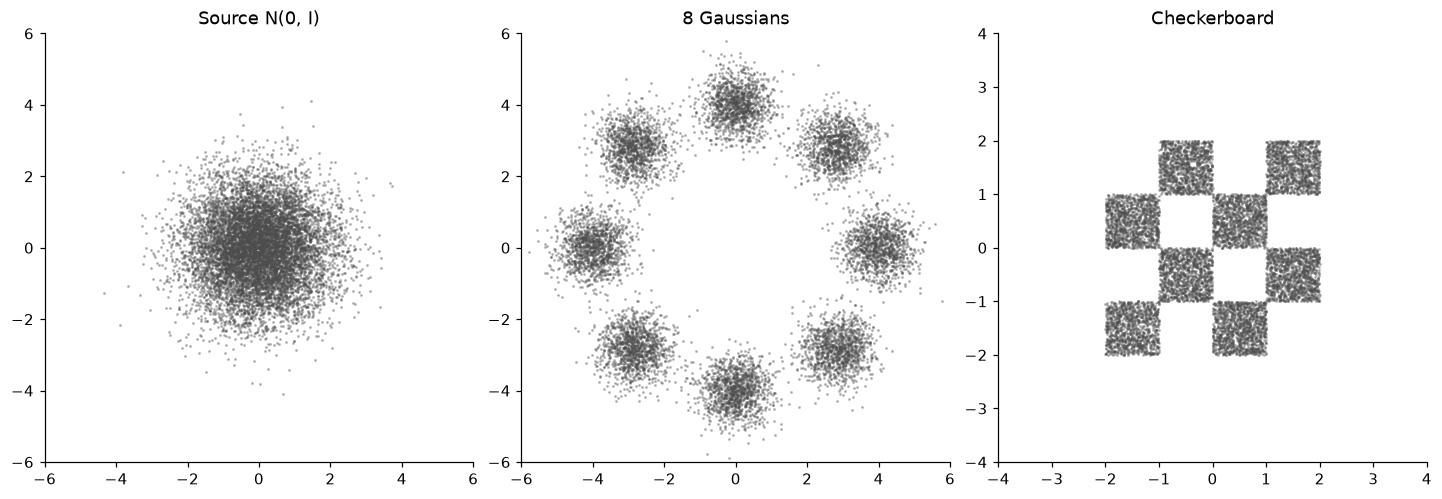

8 Gaussians   mean=[-0.06  0.  ]  std=[2.87 2.87]
Checkerboard  mean=[ 0.02 -0.01]  std=[1.15 1.15]


In [6]:
g = torch.Generator().manual_seed(0)
source = sample_standard_normal(10_000, generator=g)
targets = {name: TARGETS[name](10_000, generator=g) for name in NAMES}

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), constrained_layout=True)
scatter(axes[0], source, "0.3")
setup_ax(axes[0], 6.0, "Source N(0, I)")
for ax, name in zip(axes[1:], NAMES):
    scatter(ax, targets[name], "0.3")
    setup_ax(ax, LIM[name], TITLES[name])
plt.show()
for name in NAMES:
    x = targets[name]
    print(f"{TITLES[name]:13s} mean={x.mean(0).numpy().round(2)}  std={x.std(0).numpy().round(2)}")

## 3. Model

A small fully connected network with $t$ as an extra input: the input is $[x, t]\in\mathbb R^3$, followed by
4 hidden layers of 256 units with SiLU activations, $\mathrm{SiLU}(z) = z\,\mathrm{sigmoid}(z)$, and a linear
output in $\mathbb R^2$. SiLU is smooth, so the learned field is smooth — RK4 reaches its 4th order only for a
smooth right-hand side. One separate network is trained per target. (The paper used 5 layers of 512 units for
its 2-D example, Appendix E; a smaller network is enough here.)

`forward(t, x)` accepts either one time per point (training: `t` of shape `(n, 1)`) or a single time for the
whole batch (ODE solver: a scalar), which is broadcast to `(n, 1)` and concatenated to `x`.

In [7]:
class VelocityMLP(nn.Module):
    def __init__(self, dim=2, hidden_dim=256, n_layers=4):
        super().__init__()
        layers = [nn.Linear(dim + 1, hidden_dim), nn.SiLU()]
        for _ in range(n_layers - 1):
            layers += [nn.Linear(hidden_dim, hidden_dim), nn.SiLU()]
        layers.append(nn.Linear(hidden_dim, dim))
        self.net = nn.Sequential(*layers)

    def forward(self, t, x):
        t = torch.as_tensor(t, dtype=x.dtype, device=x.device)
        t = t.reshape(1, 1).expand(x.shape[0], 1) if t.numel() == 1 else t.reshape(-1, 1)
        return self.net(torch.cat([x, t], dim=1))


print(VelocityMLP())
print("trainable parameters:", sum(p.numel() for p in VelocityMLP().parameters()))

VelocityMLP(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=256, bias=True)
    (1): SiLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): SiLU()
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): SiLU()
    (6): Linear(in_features=256, out_features=256, bias=True)
    (7): SiLU()
    (8): Linear(in_features=256, out_features=2, bias=True)
  )
)
trainable parameters: 198914


## 4. Training

Each iteration draws a fresh batch of $B = 1024$ independent triples $(x_0, x_1, t)$ and takes one Adam step on
the CFM loss (Eq. 23). Settings: 20 000 iterations, learning rate decayed from $10^{-3}$ to $10^{-5}$ with a cosine
schedule (large steps first, then small steps to settle on the conditional mean despite the irreducible noise of
the loss), gradient norm clipped at 1. A single seeded generator drives all randomness, so training is
reproducible on CPU.

Training takes about 4–5 minutes per target on a CPU. Trained weights and loss histories are cached in
`checkpoints/`; re-running the notebook loads them (set `RETRAIN = True` to train again).

In [8]:
def train_flow_matching(model, sample_target, *, n_iters=20_000, batch_size=1024,
                        lr=1e-3, lr_min=1e-5, grad_clip=1.0, seed=0, log_every=2_000):
    gen = torch.Generator().manual_seed(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    losses, start = [], time.perf_counter()
    for i in range(n_iters):
        cur_lr = lr_min + 0.5 * (lr - lr_min) * (1 + math.cos(math.pi * i / (n_iters - 1)))
        for group in optimizer.param_groups:
            group["lr"] = cur_lr
        x1 = sample_target(batch_size, generator=gen)
        x0 = sample_standard_normal(batch_size, generator=gen)
        t = sample_time(batch_size, generator=gen)
        loss = cfm_loss(model, x0, x1, t)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()
        losses.append(loss.item())
        if (i + 1) % log_every == 0:
            print(f"iter {i + 1:>6d}   loss {sum(losses[-log_every:]) / log_every:.3f}"
                  f"   lr {cur_lr:.1e}   {time.perf_counter() - start:.0f} s")
    return losses


models, losses = {}, {}
for name in NAMES:
    torch.manual_seed(0)
    models[name] = VelocityMLP()
    path = CHECKPOINTS / f"flow_matching_2d_{name}.pt"
    if path.exists() and not RETRAIN:
        saved = torch.load(path)
        models[name].load_state_dict(saved["weights"])
        losses[name] = saved["losses"]
        print(f"{name}: loaded {path.name}")
    else:
        print(f"=== {name} ===")
        losses[name] = train_flow_matching(models[name], TARGETS[name])
        torch.save({"weights": models[name].state_dict(), "losses": losses[name]}, path)

8gaussians: loaded flow_matching_2d_8gaussians.pt
checkerboard: loaded flow_matching_2d_checkerboard.pt


### 4.1 Training loss

Per-iteration loss (light) and its moving average over 200 iterations (dark). For 8 Gaussians the dashed line
is the smallest achievable value of the loss, $\mathbb E\|X_1-X_0-u_t(X_t)\|^2$, estimated by Monte Carlo with
the exact field $u_t$ of Section 1.5; the trained network is evaluated on the same Monte-Carlo sample.

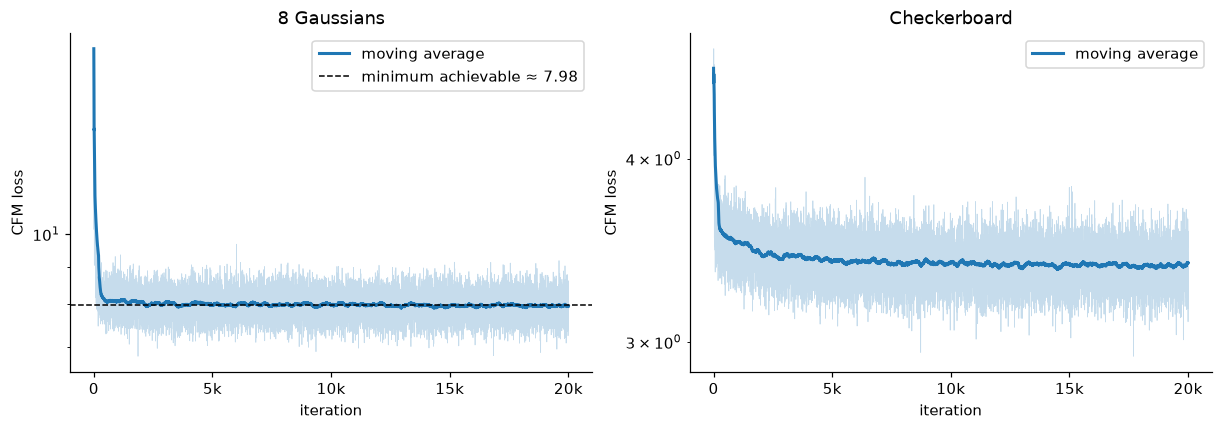

8 Gaussians   loss: first 100 iterations 10.30, last 1000 iterations 7.96
Checkerboard  loss: first 100 iterations 3.88, last 1000 iterations 3.39
8 Gaussians, same Monte-Carlo sample: exact field 7.981, trained network 7.983


In [9]:
def moving_average(values, window=200):
    x = torch.tensor(values)
    csum = torch.cat([torch.zeros(1), x.cumsum(0)])
    idx = torch.arange(1, len(x) + 1)
    lo = (idx - window).clamp(min=0)
    return (csum[idx] - csum[lo]) / (idx - lo)


g = torch.Generator().manual_seed(5)
n_mc = 500_000
x0_mc = sample_standard_normal(n_mc, generator=g)
x1_mc = sample_eight_gaussians(n_mc, generator=g)
t_mc = sample_time(n_mc, generator=g)
with torch.no_grad():
    LOSS_FLOOR = cfm_loss(eight_gaussians_velocity, x0_mc, x1_mc, t_mc).item()
    loss_net = cfm_loss(models["8gaussians"], x0_mc, x1_mc, t_mc).item()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for ax, name in zip(axes, NAMES):
    ax.plot(losses[name], color="C0", alpha=0.25, lw=0.5)
    ax.plot(moving_average(losses[name]), color="C0", lw=2, label="moving average")
    if name == "8gaussians":
        ax.axhline(LOSS_FLOOR, color="k", ls="--", lw=1, label=f"minimum achievable ≈ {LOSS_FLOOR:.2f}")
    ax.set_yscale("log")
    ax.set_xticks([0, 5_000, 10_000, 15_000, 20_000], ["0", "5k", "10k", "15k", "20k"])
    ax.set_xlabel("iteration")
    ax.set_ylabel("CFM loss")
    ax.set_title(TITLES[name])
    ax.legend()
plt.show()

for name in NAMES:
    print(f"{TITLES[name]:13s} loss: first 100 iterations {sum(losses[name][:100]) / 100:.2f}, "
          f"last 1000 iterations {sum(losses[name][-1000:]) / 1000:.2f}")
print(f"8 Gaussians, same Monte-Carlo sample: exact field {LOSS_FLOOR:.3f}, trained network {loss_net:.3f}")

**Observations.** Both losses drop within the first ~1 000 iterations (8 Gaussians: 10.3 → ≈ 8.2;
checkerboard: 3.9 → ≈ 3.5) and then level off **far above zero**: the mean over the last 1 000 iterations is
7.96 and 3.39. This is expected (Section 1.5): the target $X_1-X_0$ has an irreducible spread at every point
$(t, x_t)$, so the best possible network still pays $\mathbb E\,\mathrm{tr}\,\mathrm{Cov}(X_1-X_0\mid t, X_t)$.
For 8 Gaussians this floor is known: on the same Monte-Carlo sample the exact field gives 7.981 and the
trained network 7.983 — the network has essentially reached the conditional mean. (For scale: a network that
always outputs zero would score $\mathbb E\|X_1-X_0\|^2 = 18.5$ and $4.67$.) The per-iteration curve stays noisy
until the end because every batch is fresh and the loss itself is a noisy estimate; the cosine decay of the
learning rate removes the slow drift of the moving average in the second half of training.

## 5. Generated samples vs target

10 000 samples generated with RK4 (100 steps) next to 10 000 fresh target samples, and both overlaid. The
numbers under the figure are a target-specific score: the share of samples within $3s = 1.5$ of the nearest
centre (8 Gaussians) or inside the black squares (checkerboard), for generated and for real samples.

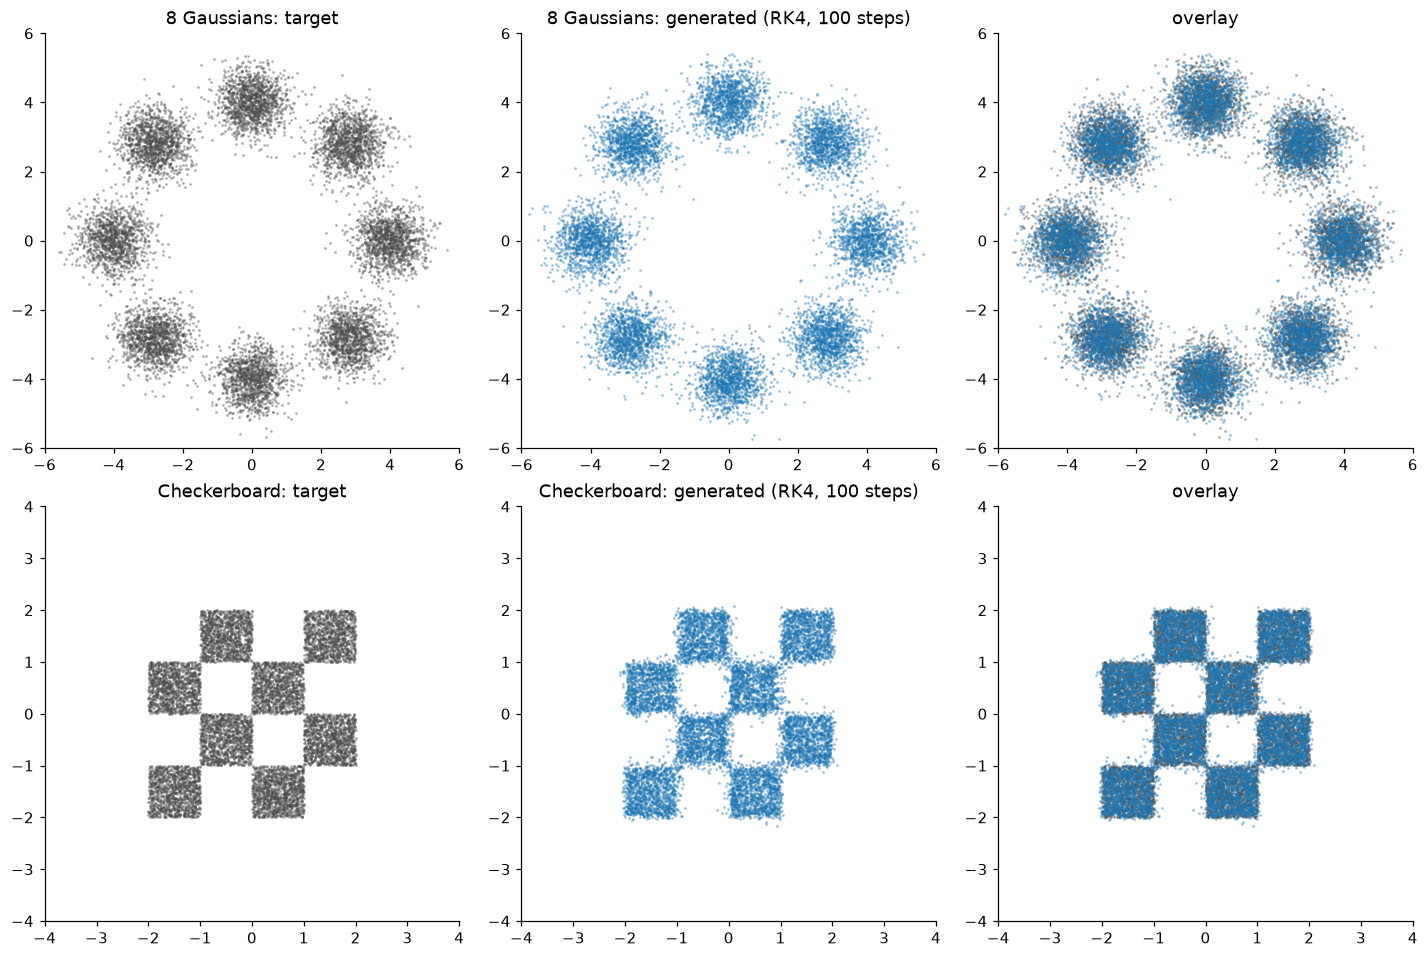

8 Gaussians: within 3 std of a centre — generated 98.7 %, target 99.0 %
             share of each mode: [0.115, 0.124, 0.129, 0.127, 0.125, 0.126, 0.126, 0.129]
Checkerboard: inside the black squares — generated 94.1 %, target 100.0 %


In [10]:
def eight_gaussians_in_mode(x, radius=4.0, std=0.5):
    dist, nearest = torch.cdist(x, eight_gaussians_centers(radius)).min(dim=1)
    in_mode = dist <= 3 * std
    shares = torch.bincount(nearest[in_mode], minlength=8) / in_mode.sum()
    return in_mode.float().mean().item(), shares


def checkerboard_in_support(x):
    cell = torch.floor(x).long()
    inside = (x.abs() <= 2).all(dim=1) & ((cell[:, 0] + cell[:, 1]) % 2 == 0)
    return inside.float().mean().item()


def score(name, x):
    return eight_gaussians_in_mode(x)[0] if name == "8gaussians" else checkerboard_in_support(x)


g = torch.Generator().manual_seed(1)
x0_eval = sample_standard_normal(10_000, generator=g)  # the same noise is reused below
real = {name: TARGETS[name](10_000, generator=g) for name in NAMES}
generated = {name: sample_flow(models[name], 10_000, n_steps=100, x0=x0_eval) for name in NAMES}

fig, axes = plt.subplots(2, 3, figsize=(13, 8.6), constrained_layout=True)
for row, name in enumerate(NAMES):
    lim = LIM[name]
    scatter(axes[row, 0], real[name], "0.3")
    setup_ax(axes[row, 0], lim, f"{TITLES[name]}: target")
    scatter(axes[row, 1], generated[name], "C0")
    setup_ax(axes[row, 1], lim, f"{TITLES[name]}: generated (RK4, 100 steps)")
    scatter(axes[row, 2], real[name], "0.3")
    scatter(axes[row, 2], generated[name], "C0")
    setup_ax(axes[row, 2], lim, "overlay")
plt.show()

frac_gen, shares = eight_gaussians_in_mode(generated["8gaussians"])
print(f"8 Gaussians: within 3 std of a centre — generated {100 * frac_gen:.1f} %, "
      f"target {100 * eight_gaussians_in_mode(real['8gaussians'])[0]:.1f} %")
print("             share of each mode:", [round(s, 3) for s in shares.tolist()])
print(f"Checkerboard: inside the black squares — generated "
      f"{100 * checkerboard_in_support(generated['checkerboard']):.1f} %, "
      f"target {100 * checkerboard_in_support(real['checkerboard']):.1f} %")

**Observations.** * **8 Gaussians.** All 8 modes are recovered with the right size and balance: each mode
  receives 11.5–12.9 % of the in-mode samples (ideal 12.5 %), and 98.7 % of the generated points lie within
  3 std of a centre versus 99.0 % for real samples. In the overlay the two clouds are almost
  indistinguishable; the only visible defect is a few points on thin "bridges" between neighbouring modes —
  the flow is a continuous map of the plane and cannot tear the Gaussian into 8 separate pieces completely.
* **Checkerboard.** The pattern and its orientation are reproduced; 94.1 % of the samples fall inside the black
  squares (100 % for real samples). The misses sit on slightly blurred edges and at the corners where squares
  touch: the target density jumps from $1/8$ to $0$ across an edge, while the smooth network can only produce a
  smooth field and hence a slightly smoothed density.

## 6. Trajectories

Left: the **conditional** straight paths $x_t=(1-t)x_0+tx_1$ used as regression targets, for random independent
pairs — they cross each other. Right: trajectories of the **learned** flow from the same $x_0$, integrated with RK4
(100 steps): grey dots at $t=0$, orange dots at $t=1$, target samples in the background. They cannot cross, so
they bend: each point follows the *average* direction of all conditional paths through it (Section 1.5). The
number in the title is the length-weighted straightness $\sum_i|x_1^{(i)}-x_0^{(i)}|/\sum_i \text{length}_i$
(1 = perfectly straight), computed on 2 000 trajectories.

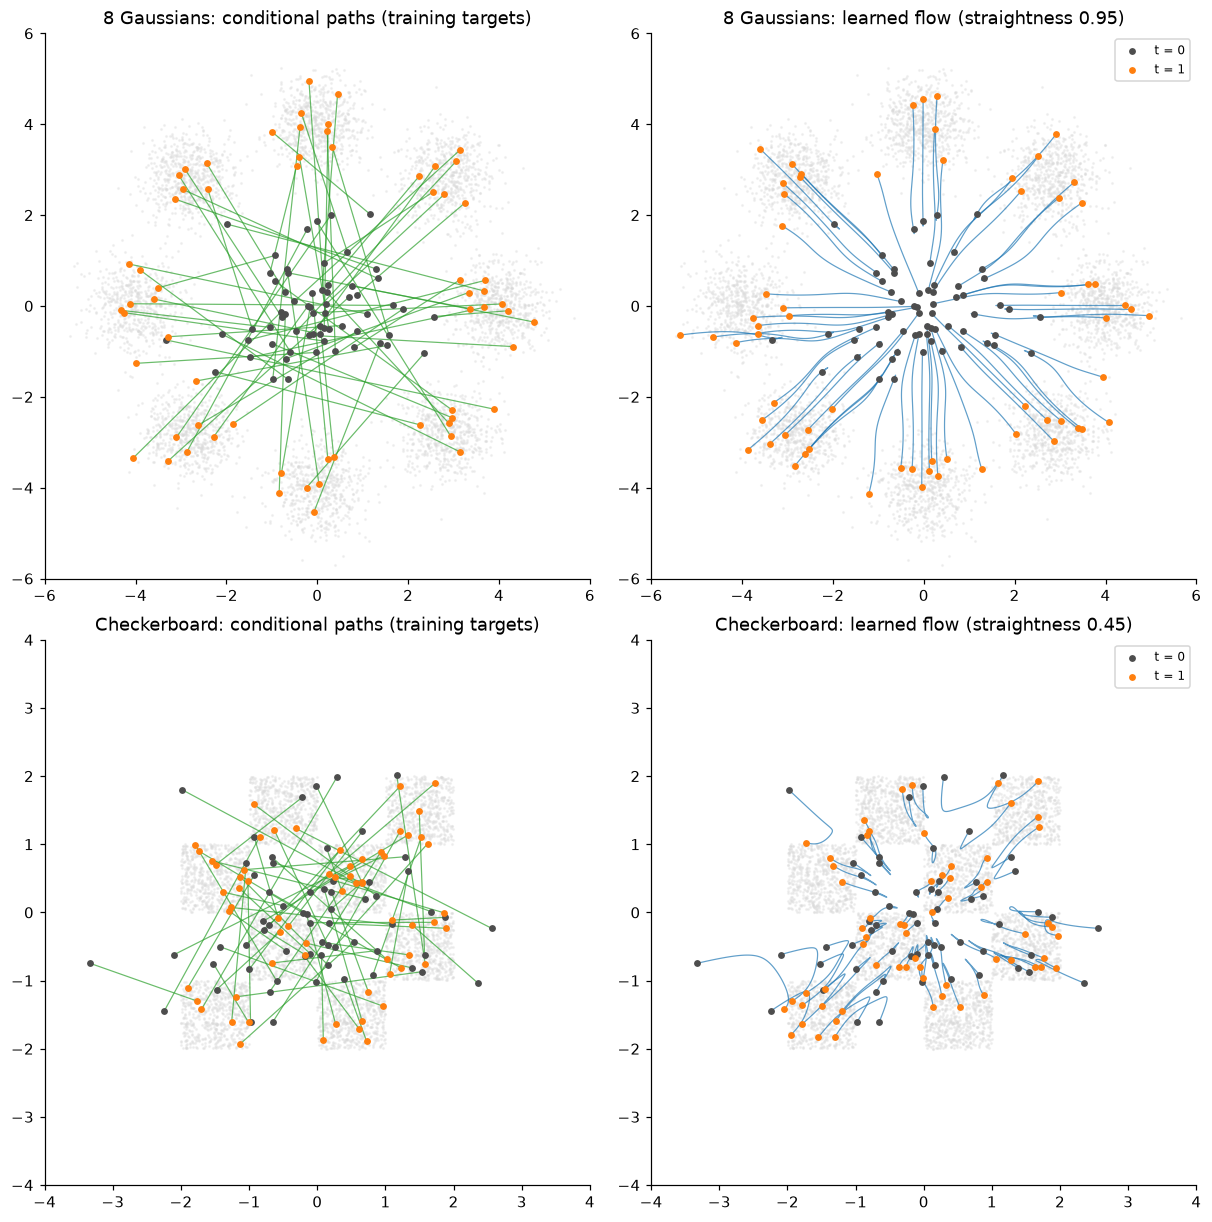

In [11]:
def straightness(traj):
    chord = (traj[-1] - traj[0]).norm(dim=-1).sum()
    length = (traj[1:] - traj[:-1]).norm(dim=-1).sum()
    return (chord / length).item()


n_tr = 64
fig, axes = plt.subplots(2, 2, figsize=(11, 11), constrained_layout=True)
for row, name in enumerate(NAMES):
    lim = LIM[name]
    x0 = x0_eval[:n_tr]
    x1 = real[name][:n_tr]
    ax = axes[row, 0]
    scatter(ax, real[name][:5_000], "0.85")
    for i in range(n_tr):
        ax.plot([x0[i, 0], x1[i, 0]], [x0[i, 1], x1[i, 1]], color="C2", lw=0.8, alpha=0.7)
    ax.scatter(x0[:, 0], x0[:, 1], s=12, color="0.3", zorder=3)
    ax.scatter(x1[:, 0], x1[:, 1], s=12, color="C1", zorder=3)
    setup_ax(ax, lim, f"{TITLES[name]}: conditional paths (training targets)")

    traj = sample_flow(models[name], 2_000, n_steps=100, x0=x0_eval[:2_000], return_trajectory=True)
    ax = axes[row, 1]
    scatter(ax, real[name][:5_000], "0.85")
    for i in range(n_tr):
        ax.plot(traj[:, i, 0], traj[:, i, 1], color="C0", lw=0.8, alpha=0.7)
    ax.scatter(traj[0, :n_tr, 0], traj[0, :n_tr, 1], s=12, color="0.3", zorder=3, label="t = 0")
    ax.scatter(traj[-1, :n_tr, 0], traj[-1, :n_tr, 1], s=12, color="C1", zorder=3, label="t = 1")
    ax.legend(loc="upper right", fontsize=8)
    setup_ax(ax, lim, f"{TITLES[name]}: learned flow (straightness {straightness(traj):.2f})")
plt.show()

### 6.1 The marginal path $p_t$

The whole generated cloud at intermediate times — the learned analogue of Fig. 4 (left) of the paper.

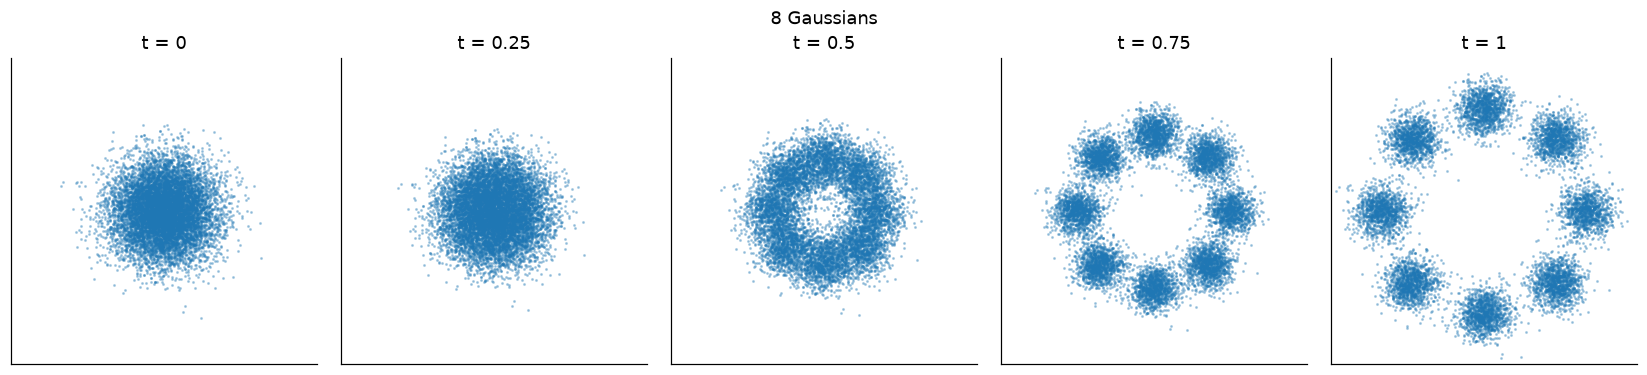

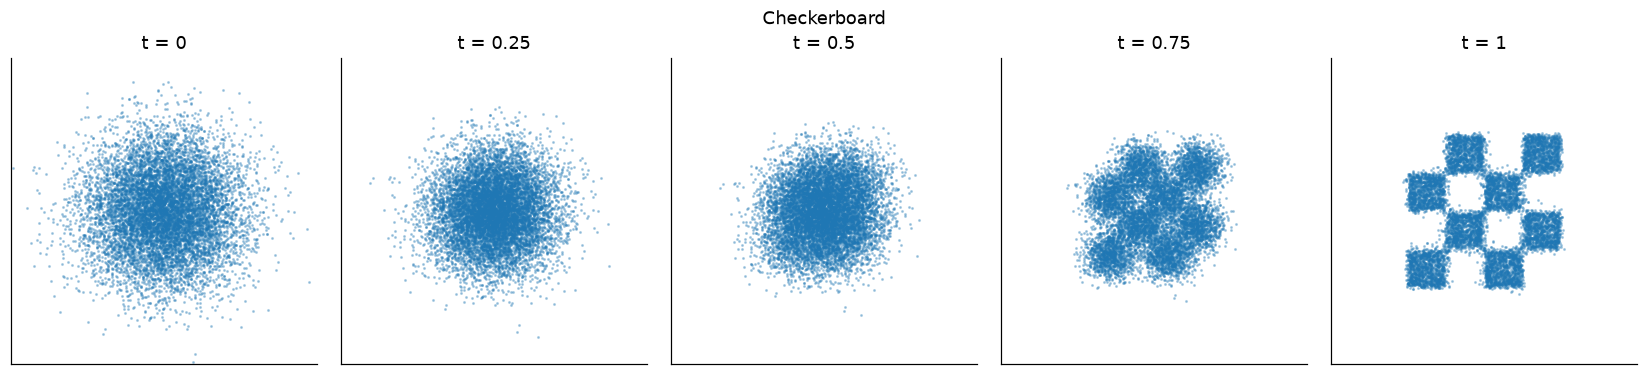

In [12]:
snapshot_times = [0.0, 0.25, 0.5, 0.75, 1.0]
for name in NAMES:
    path = sample_flow(models[name], 10_000, n_steps=100, x0=x0_eval, return_trajectory=True)
    fig, axes = plt.subplots(1, len(snapshot_times), figsize=(15, 3.3), constrained_layout=True)
    for ax, s in zip(axes, snapshot_times):
        scatter(ax, path[round(s * 100)], "C0")
        setup_ax(ax, LIM[name], f"t = {s:g}")
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(TITLES[name])
    plt.show()

**Observations.** * The conditional training paths (left) cross everywhere; the learned trajectories (right) never cross,
  exactly as predicted for an ODE flow. The flow therefore pairs noise and data points differently from the
  random independent pairs used for training — each particle follows the *average* direction at its location.
* **8 Gaussians:** the trajectories form a radial fan and are nearly straight (straightness 0.95); the bending
  happens mainly early, while a particle "chooses" its mode. The marginal path first contracts slightly
  ($u_0 = -x$), becomes a ring around $t \approx 0.5$ and splits into 8 clusters by $t \approx 0.75$.
* **Checkerboard:** the paths are short and strongly curved (straightness 0.45) — each particle moves only a
  small distance and turns towards the nearest black square; the square pattern appears only late, between
  $t \approx 0.5$ and $0.75$. This is the analogue of Fig. 4 (left) of the paper for our learned field.

## 7. Learned velocity field

$v_\theta(t, x)$ on a $25\times25$ grid at $t = 0, 0.25, 0.5, 0.75, 1$. Arrows are normalised and show the
**direction**; colour shows the **speed** $|v_\theta|$. Grey dots are samples of $x_t=(1-t)X_0+tX_1$ at the same
time — the region where the field is actually trained; outside it the network extrapolates. Expected from
Section 1.5: $v(0,x)\approx -x$ and $v(1,x)\approx x$ on the support of $q$.

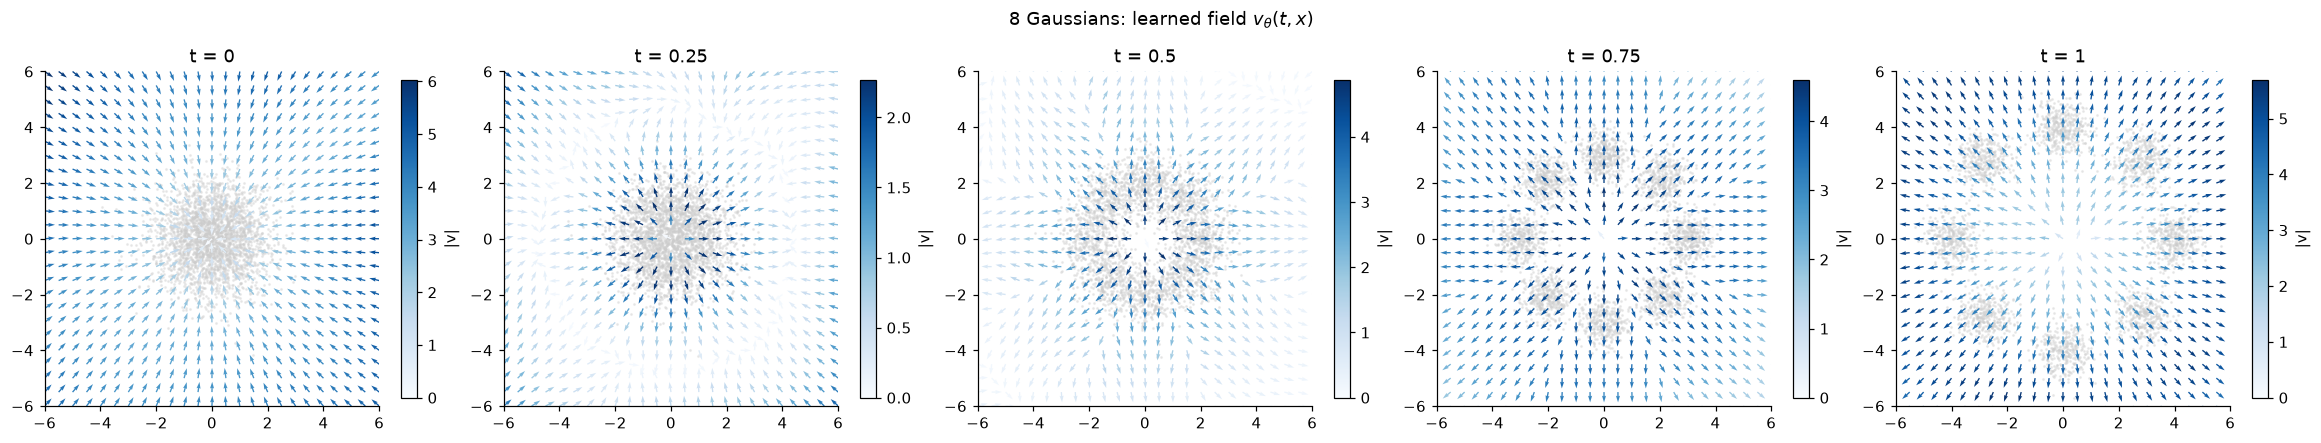

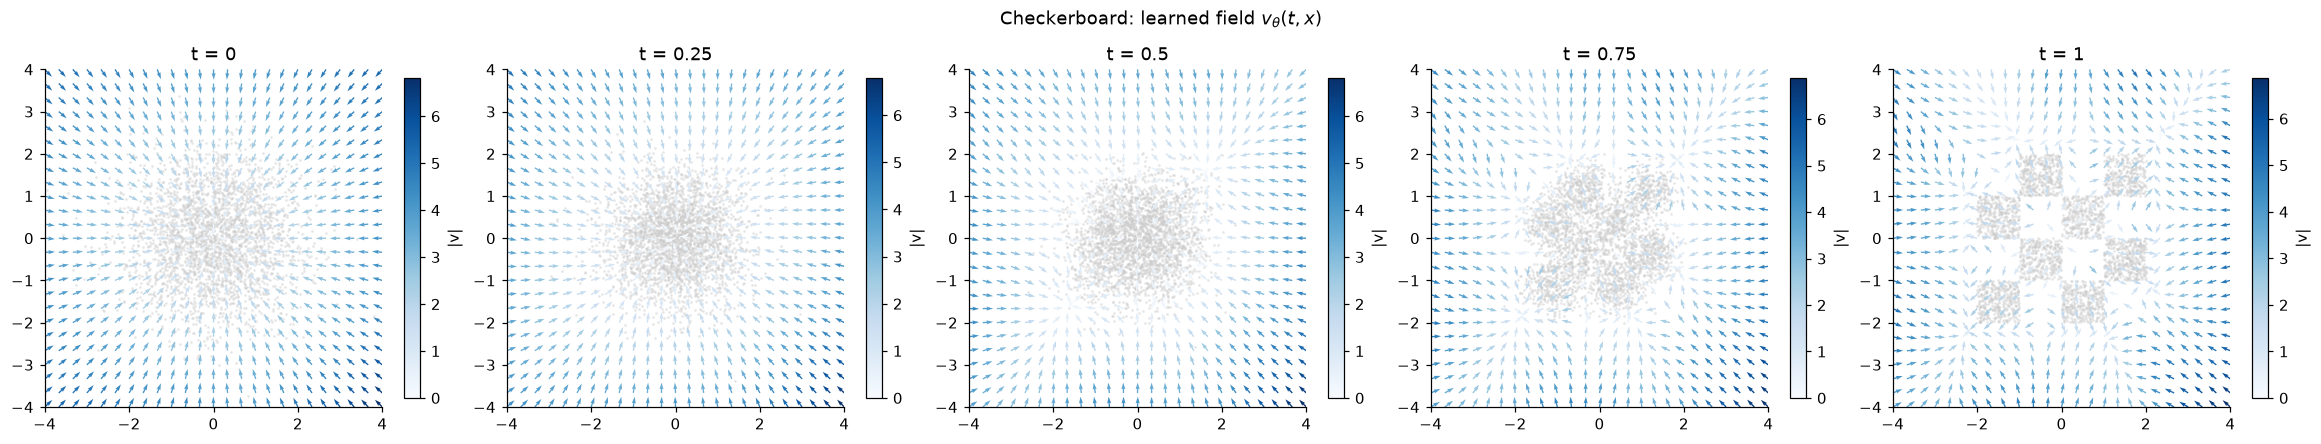

In [13]:
TIMES = [0.0, 0.25, 0.5, 0.75, 1.0]


def plot_velocity_field(ax, v, t_value, lim, background=None, grid_size=25):
    grid = torch.linspace(-lim, lim, grid_size)
    gx, gy = torch.meshgrid(grid, grid, indexing="xy")
    points = torch.stack([gx.reshape(-1), gy.reshape(-1)], dim=1)
    with torch.no_grad():
        vel = v(t_value, points)
    speed = vel.norm(dim=1)
    direction = vel / speed.clamp(min=1e-8).unsqueeze(1)
    if background is not None:
        scatter(ax, background, "0.8")
    q = ax.quiver(points[:, 0], points[:, 1], direction[:, 0], direction[:, 1], speed,
                  cmap="Blues", clim=(0, speed.max()), scale=grid_size * 1.3, width=0.004)
    setup_ax(ax, lim, f"t = {t_value:g}")
    return q


n_bg = 3_000
for name in NAMES:
    fig, axes = plt.subplots(1, len(TIMES), figsize=(4.2 * len(TIMES), 4), constrained_layout=True)
    for ax, t_value in zip(axes, TIMES):
        xt = interpolate(x0_eval[:n_bg], real[name][:n_bg], torch.full((n_bg, 1), t_value))
        q = plot_velocity_field(ax, models[name], t_value, LIM[name], background=xt)
        fig.colorbar(q, ax=ax, shrink=0.8, label="|v|")
    fig.suptitle(f"{TITLES[name]}: learned field $v_\\theta(t, x)$")
    plt.show()

### 7.1 Comparison with the exact field (8 Gaussians)

The exact field $u_t$ of Section 1.5 next to the learned one at $t = 0.5$, the error map
$|v_\theta - u_t|$, and the relative error $\mathbb E\,|v_\theta-u_t| \,/\, \mathbb E\,|u_t|$ measured where
it matters, i.e. on samples of $p_t$.

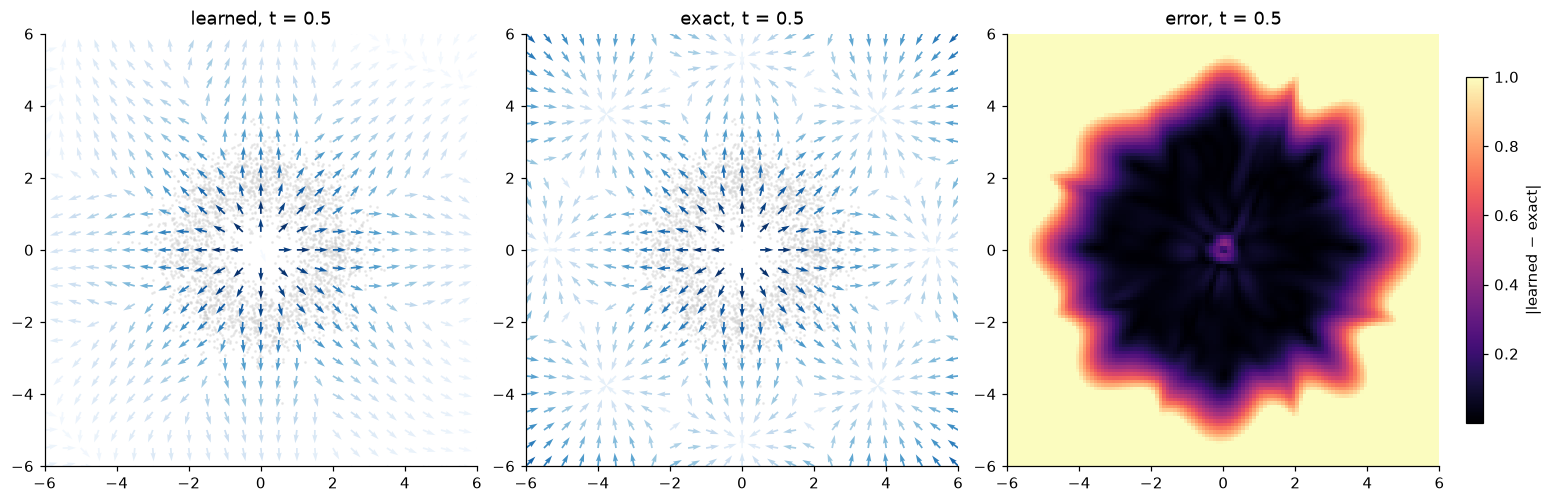

   t   relative error on samples of p_t
 0.00    4.57 %
 0.25    1.74 %


 0.50    0.93 %
 0.75    0.89 %
 1.00    1.18 %


In [14]:
model = models["8gaussians"]
n_bg = 3_000
xt = interpolate(x0_eval[:n_bg], real["8gaussians"][:n_bg], torch.full((n_bg, 1), 0.5))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), constrained_layout=True)
plot_velocity_field(axes[0], model, 0.5, 6.0, background=xt)
axes[0].set_title("learned, t = 0.5")
plot_velocity_field(axes[1], eight_gaussians_velocity, 0.5, 6.0, background=xt)
axes[1].set_title("exact, t = 0.5")
grid = torch.linspace(-6, 6, 120)
gx, gy = torch.meshgrid(grid, grid, indexing="xy")
pts = torch.stack([gx.reshape(-1), gy.reshape(-1)], dim=1)
with torch.no_grad():
    err = (model(0.5, pts) - eight_gaussians_velocity(0.5, pts)).norm(dim=1).reshape(120, 120)
im = axes[2].imshow(err, origin="lower", extent=[-6, 6, -6, 6], cmap="magma", vmax=1.0)
fig.colorbar(im, ax=axes[2], shrink=0.8, label="|learned − exact|")
axes[2].set_title("error, t = 0.5")
plt.show()

g = torch.Generator().manual_seed(6)
x0_c = sample_standard_normal(20_000, generator=g)
x1_c = sample_eight_gaussians(20_000, generator=g)
print("   t   relative error on samples of p_t")
with torch.no_grad():
    for t_value in TIMES:
        xt = interpolate(x0_c, x1_c, torch.full((20_000, 1), t_value))
        exact = eight_gaussians_velocity(t_value, xt)
        rel = (model(t_value, xt) - exact).norm(dim=1).mean() / exact.norm(dim=1).mean()
        print(f"{t_value:5.2f}   {100 * rel.item():5.2f} %")

**Observations.** * **$t = 0$:** for both targets all arrows point to the origin and the speed grows linearly with $|x|$ —
  the field is $v \approx -x$, as predicted by $u_0(x)=\mathbb E[X_1]-x$.
* **Intermediate times:** for 8 Gaussians the field splits the plane into 8 angular sectors and pushes particles
  outwards along the rays towards the modes; for the checkerboard it is weak until $t \approx 0.5$ and then
  develops the square structure (arrows pointing into the black squares) around $t = 0.75$.
* **$t = 1$:** on the support of the target the field points away from the origin, $v \approx x$; outside the grey
  region of $x_t$ samples (e.g. the corners) the network was never trained and extrapolates — those arrows carry
  no meaning, but no particle ever goes there.
* **Exact field (8 Gaussians):** the learned and exact fields are visually identical where the particles are; the
  relative error on samples of $p_t$ is 0.9–1.7 % for $t \ge 0.25$ and 4.6 % at $t = 0$ (where the speeds
  themselves are small). The error map is dark over the region covered by $p_t$ and grows only far from it.

## 8. Number of Runge-Kutta steps

Samples generated from the **same** noise `x0_eval` with $N = 1, 2, 3, 5, 10, 20, 50, 100$ RK4 steps
(NFE $=4N$).

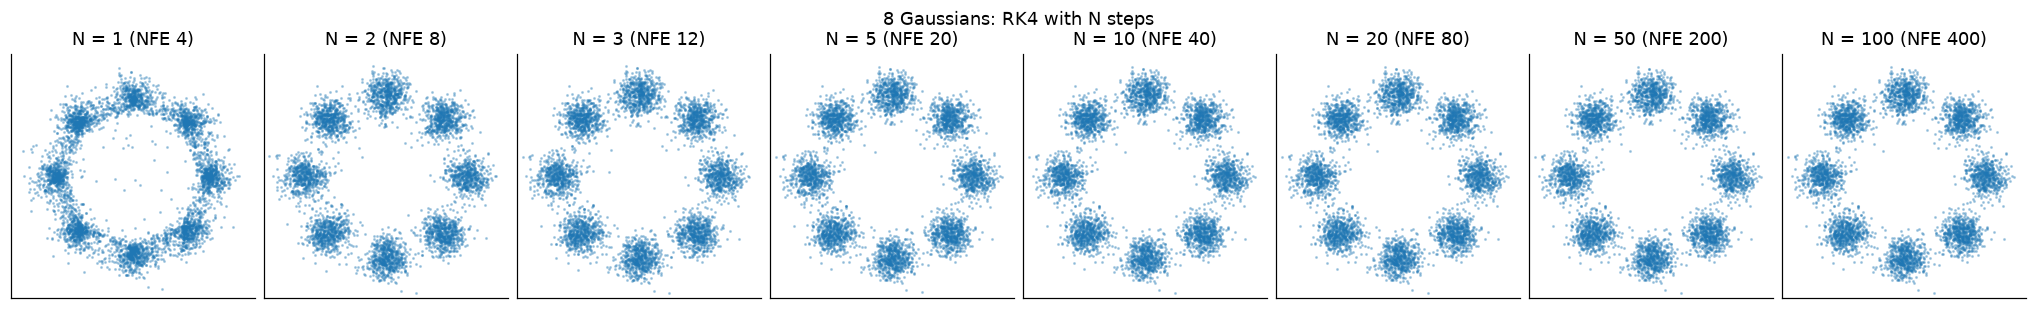

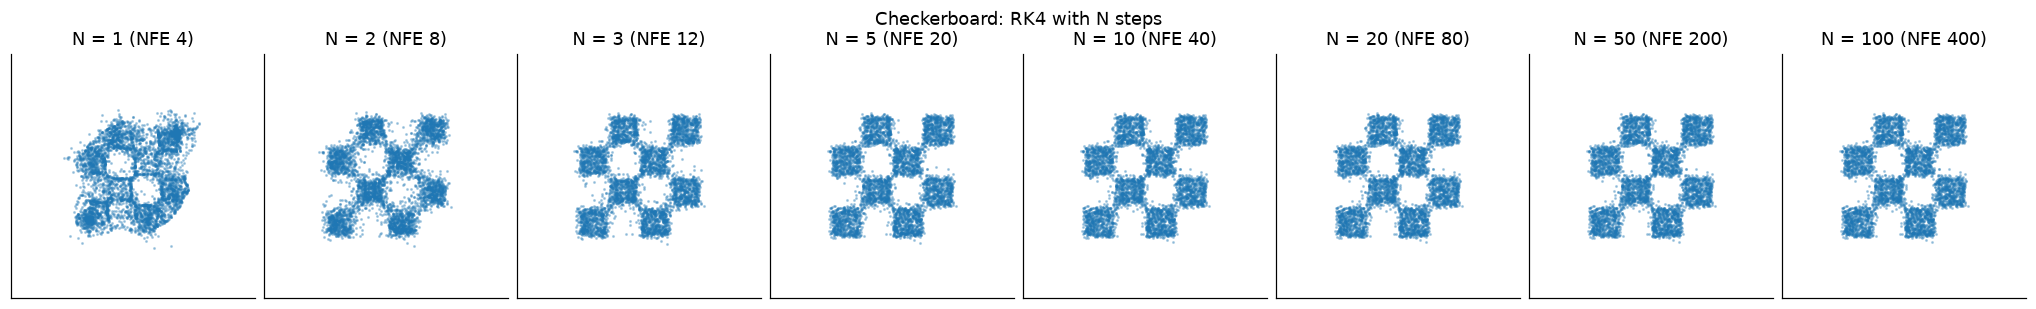

In [15]:
STEPS = [1, 2, 3, 5, 10, 20, 50, 100]
sweep = {}
for name in NAMES:
    sweep[name] = {n: sample_flow(models[name], 5_000, n_steps=n, x0=x0_eval[:5_000]) for n in STEPS}
    fig, axes = plt.subplots(1, len(STEPS), figsize=(2.3 * len(STEPS), 2.7), constrained_layout=True)
    for ax, n in zip(axes, STEPS):
        scatter(ax, sweep[name][n], "C0")
        setup_ax(ax, LIM[name], f"N = {n} (NFE {4 * n})")
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(f"{TITLES[name]}: RK4 with N steps")
    plt.show()

Quantitative view on the same noise:

* **ODE error** — mean distance $|x_N - x_{\mathrm{ref}}|$ to a reference solution with 500 RK4 steps: the pure
  discretisation error, expected to decay as $N^{-4}$ (slope $-4$ on a log–log plot) until float32 round-off;
* **sample quality** — the target-specific score of Section 5.

8 Gaussians   ODE error: N=1: 2.7e-01, N=2: 3.7e-02, N=3: 2.2e-02, N=5: 3.7e-03, N=10: 2.8e-04, N=20: 1.9e-05, N=50: 1.7e-06, N=100: 1.6e-06
              quality:   N=1: 0.973, N=2: 0.982, N=3: 0.984, N=5: 0.985, N=10: 0.987, N=20: 0.987, N=50: 0.987, N=100: 0.987


Checkerboard  ODE error: N=1: 2.1e-01, N=2: 7.1e-02, N=3: 1.6e-02, N=5: 2.6e-03, N=10: 1.5e-04, N=20: 1.1e-05, N=50: 7.5e-07, N=100: 6.3e-07
              quality:   N=1: 0.713, N=2: 0.911, N=3: 0.940, N=5: 0.944, N=10: 0.941, N=20: 0.942, N=50: 0.942, N=100: 0.942


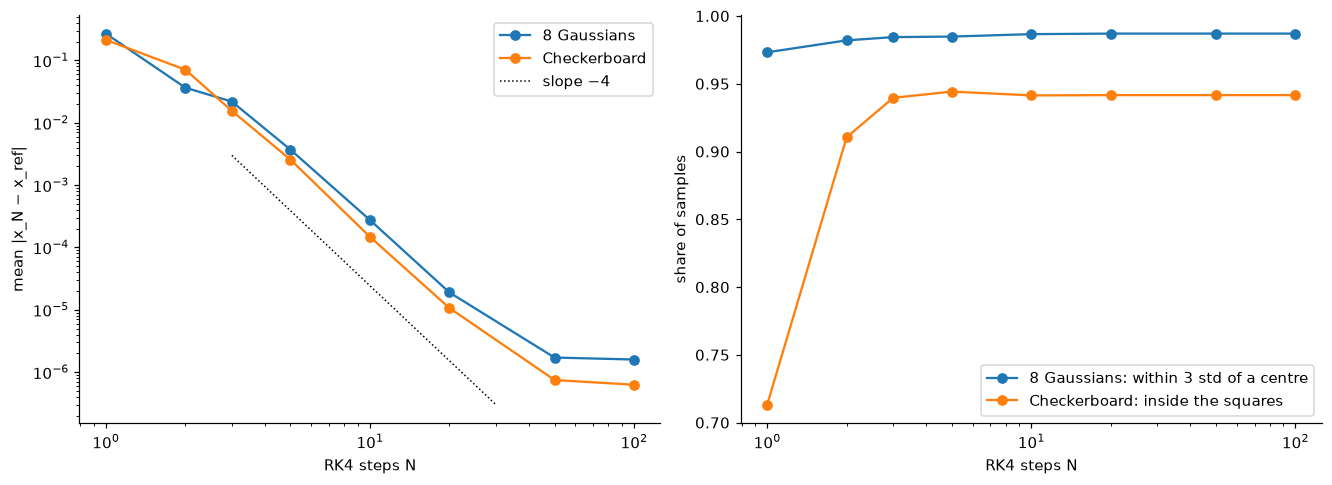

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
for name, color in zip(NAMES, ["C0", "C1"]):
    reference = sample_flow(models[name], 5_000, n_steps=500, x0=x0_eval[:5_000])
    errors = [(sweep[name][n] - reference).norm(dim=1).mean().item() for n in STEPS]
    quality = [score(name, sweep[name][n]) for n in STEPS]
    axes[0].plot(STEPS, errors, "o-", color=color, label=TITLES[name])
    axes[1].plot(STEPS, quality, "o-", color=color,
                 label="8 Gaussians: within 3 std of a centre" if name == "8gaussians"
                 else "Checkerboard: inside the squares")
    print(f"{TITLES[name]:13s} ODE error: " + ", ".join(f"N={n}: {e:.1e}" for n, e in zip(STEPS, errors)))
    print(f"{'':13s} quality:   " + ", ".join(f"N={n}: {q:.3f}" for n, q in zip(STEPS, quality)))
n_ref = torch.tensor([3.0, 30.0])
axes[0].plot(n_ref, 3e-3 * (n_ref / 3) ** -4, "k:", lw=1, label="slope −4")
axes[0].set(xscale="log", yscale="log", xlabel="RK4 steps N", ylabel="mean |x_N − x_ref|")
axes[0].legend()
axes[1].set(xscale="log", xlabel="RK4 steps N", ylabel="share of samples")
axes[1].legend()
plt.show()

**Observations.** * With **$N = 1$** (4 network evaluations) the samples are clearly wrong: the 8 Gaussians merge into a ring and
  the checkerboard is smeared (71 % inside the squares). With $N = 2$ the picture is almost right, and from
  **$N \approx 3$–5 (12–20 evaluations)** nothing changes visually any more.
* The quality scores plateau at the same point: 8 Gaussians 0.973 → 0.985 at $N = 5$ → 0.987; checkerboard
  0.713 → 0.911 → 0.940 at $N = 3$ → 0.942.
* The ODE error decays with slope ≈ −4 on the log–log plot (e.g. 3.7·10⁻³ → 1.9·10⁻⁵ from $N = 5$ to $N = 20$,
  checkerboard 2.6·10⁻³ → 1.1·10⁻⁵), as expected for a 4th-order method, until it hits float32 round-off
  (~10⁻⁶) at $N \approx 50$.
* Few steps are enough because the learned flow is smooth and its trajectories are only mildly curved — the point
  made in Sec. 6.2 (Fig. 4 right, Fig. 7) of the paper. The checkerboard, whose trajectories are more curved,
  needs a step or two more than the 8 Gaussians for the same quality.

## 9. Conclusions

* Conditional Flow Matching with the OT path and $\sigma_{\min}=0$ — the linear interpolant
  $x_t=(1-t)X_0+tX_1$ with target $X_1-X_0$ — learns both targets with a small MLP (4×256, SiLU) in about
  4–5 minutes per target on a CPU, without simulating the ODE during training.
* The loss plateaus at a positive value (7.96 and 3.39), because the network learns the **average** of
  $X_1-X_0$ over all pairs passing through a point. For 8 Gaussians the trained network reaches the analytic
  minimum (7.983 vs 7.981) and matches the exact field $u_t(x)=\mathbb E[X_1-X_0\mid X_t=x]$ to ≈ 1–2 %.
* The learned velocity field behaves as the theory predicts: $v \approx -x$ at $t=0$, splits the plane into
  basins of the modes / squares at intermediate times, and $v \approx x$ on the support at $t=1$.
* Learned trajectories are non-crossing, curved averages of the straight conditional paths: nearly straight for
  8 Gaussians (straightness 0.95), strongly curved for the checkerboard (0.45). The marginal flow is not an OT
  map, even though every conditional path is one.
* Generated samples match the targets closely (98.7 % vs 99.0 % within 3 std, all 8 modes balanced; 94.1 % inside
  the squares); the remaining defects are thin bridges between modes and blurred square edges, both caused by
  the smoothness and continuity of the learned flow.
* RK4 shows its 4th-order convergence, and 3–5 steps (12–20 network evaluations) already give samples that are
  indistinguishable from 100 steps.
* Possible improvements: couplings that straighten the flow, such as mini-batch OT (Tong et al., 2024) or
  reflow (Liu et al., 2022), would allow even fewer steps; a larger network or longer training would sharpen the
  square edges.

## 10. References

1. Y. Lipman, R. T. Q. Chen, H. Ben-Hamu, M. Nickel, M. Le. *Flow Matching for Generative Modeling.* ICLR 2023.
   arXiv:2210.02747. — **the paper this notebook implements** (Sec. 2–4, 6.2, Appendix A–B, E).
2. R. T. Q. Chen, Y. Rubanova, J. Bettencourt, D. Duvenaud. *Neural Ordinary Differential Equations.* NeurIPS 2018.
   arXiv:1806.07366.
3. W. Grathwohl, R. T. Q. Chen, J. Bettencourt, I. Sutskever, D. Duvenaud. *FFJORD: Free-form Continuous Dynamics
   for Scalable Reversible Generative Models.* ICLR 2019. arXiv:1810.01367. — origin of the 2-D toy datasets.
4. X. Liu, C. Gong, Q. Liu. *Flow Straight and Fast: Learning to Generate and Transfer Data with Rectified Flow.*
   ICLR 2023. arXiv:2209.03003.
5. M. S. Albergo, E. Vanden-Eijnden. *Building Normalizing Flows with Stochastic Interpolants.* ICLR 2023.
   arXiv:2209.15571.
6. A. Tong et al. *Improving and Generalizing Flow-Based Generative Models with Minibatch Optimal Transport.*
   TMLR 2024. arXiv:2302.00482.